# Circular Molecules

> ### In this tutorial we will cover:
> - how to use the `AutoReact` class to connect two molecules
> - how to steer `AutoReact` with custom reactivity pairs

In version `v.1.3.1` we introduced a still prototype class named `AutoReact` which uses the `Reactivity` classes  to scan for compatible ways to connect two target molecules. It then picks the highest scoring pairing and links the molecules using it's reactivity rules. 

Let's have a look how to use it!

## Chemical Space in BuildAMol : Reactivities and Pairs

Let's say we have an alcohol and a carboxylic acid, chemical intuition would be that they likely would form an ester and split off a water molecule. Of course, chemical reactions are heavily influenced by their environment; solvent, pH, temperature, and so on. We couldn't hope to adequately account for all of these even if we tried, so we don't. 
Instead `AutoReact` uses a list of possible reactions that could ocurr alongside a `score` that ranks them. The class will then iterate through the pairs and scan for suitable atom groups within both molecules. Among all matches it will then pick the highest scoring one and assemble a `Linkage` using it's Reactivities and the identified atoms.


BuildAMol currently offers the following reactivities (check out the tutorial on Reactivities if you haven't yet):

In [1]:
import buildamol as bam
from buildamol.structural import reactivity

reactivity.default_reactivities()

The Reactivities are deliberately ambivalent to being a nucleophile or electrophile - all Reactivities can mechanically serve either role, irrespective of how chemically realistic that would be in a particular case. To avoid blindly searching for any permutation of the reactivities and to ground `AutoReact` in a somewhat chemically reasonable reactivity space we define a set of reactions alongside of how much weight we give each of them inside the imaginary environment that our molecules live inside. 

We can check the default reactions (pairings of reactivities) by checking out the `DEFAULT_PAIRS` dictionary which maps two names of Reactivity classes as a tuple to a `PairRule` object that stores the weight (score) that defines how likely or important we believe the particular reaction to be - higher values place a particular pair higher in the ranking and thus more likely to be chosen over other possible pairs. 

If you have a look at the dictionary below you will notice that some PairRules define a `fallback` attribute as `True`. Fallback pairs are reactions that do not follow our chemical intuition but are convenient to connect two molecules that would otherwise not assemble under the chemical space we defined for our `AutoReact` class. The class supports disabling fallbacks, however, but more on that later.

In [2]:
from buildamol.core.autoreact import DEFAULT_PAIRS
from tabulate import tabulate

table = [(k, v) for k, v in DEFAULT_PAIRS.items()]
print(tabulate(table, headers=["Key", "PairRule"]))

Key                           PairRule
----------------------------  ------------------------------------------------------------------------------------------
('Amine', 'Carboxyl')         PairRule(score=1.0, bond_order=1, label='amide', fallback=False)
('Amine', 'Ester')            PairRule(score=0.8, bond_order=1, label='amide (aminolysis)', fallback=False)
('Amine', 'Aldehyde')         PairRule(score=0.85, bond_order=2, label='imine', fallback=False)
('Amine', 'Ketone')           PairRule(score=0.75, bond_order=2, label='imine', fallback=False)
('Amine', 'AlkylHalide')      PairRule(score=0.7, bond_order=1, label='N-alkylation', fallback=False)
('Amine', 'Hydroxyl')         PairRule(score=0.3, bond_order=1, label='N-alkylation (alcohol)', fallback=False)
('Amine', 'CH')               PairRule(score=0.25, bond_order=1, label='C-N', fallback=True)
('Thiol', 'AlkylHalide')      PairRule(score=0.9, bond_order=1, label='thioether', fallback=False)
('Thiol', 'Carboxyl')         PairRule(

## Using AutoReact

The TLDR of the tutorial, basically boils down to we can connect molecules using the `autoreact` function (for full defaults, no customisability) or by setting up an instance of the `AutoReact` class (supports customisation). So to use our example of an alcohol and a carboxylic acid we could do:

Text(0.5, 1.0, 'Out')

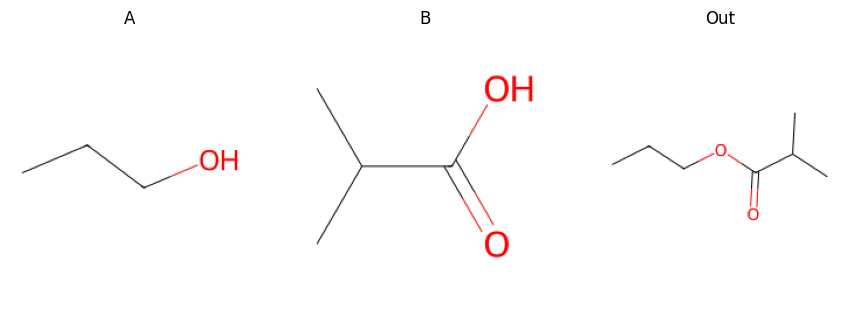

In [3]:
A = bam.read_smiles("OCCC")
B = bam.read_smiles("CC(C)C(=O)O")

out = bam.autoreact(A, B)

fig, axs = bam.utils.visual.gallery_grid([A, B, out], ncols=3)
axs[0].set_title("A")
axs[1].set_title("B")
axs[2].set_title("Out")

And that's it. Of course this is a very simply example. In case of multiple possible matches for the same reactivities the ranking will continue to count the number of bonds in the vicinity of the matched atoms to discern the less sterically hindered site. For instance we have a molecule with two hydroxyl groups, one primary and one secondary. Intuition would put the less sterically hindered primary hydroxyl group first, so that's the site that is chosen for the reaction.

Text(0.5, 1.0, 'Out')

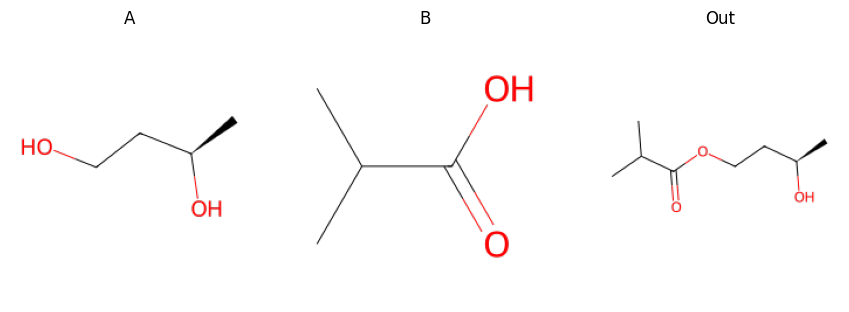

In [4]:
A = bam.read_smiles("C(O)CC(O)C")

out = bam.autoreact(A, B)
fig, axs = bam.utils.visual.gallery_grid([A, B, out], ncols=3)
axs[0].set_title("A")
axs[1].set_title("B")
axs[2].set_title("Out")

In case of multiple possible different reactions our ranking from the pairs dictionary comes into play. Whichever `PairRule` has the higher score will be the one chosen by the `AutoReact` algorithm:

Text(0.5, 1.0, 'Out')

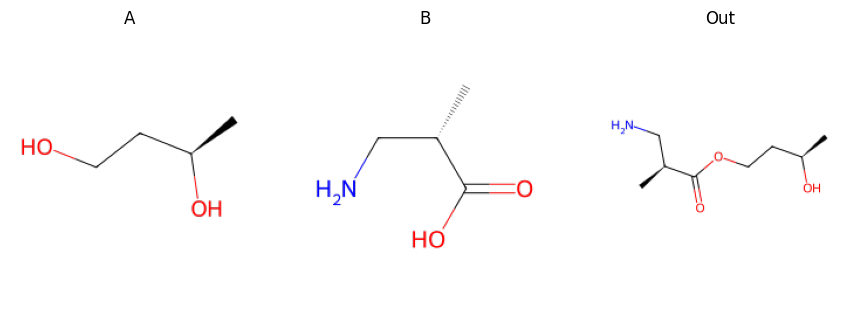

In [5]:
B = bam.read_smiles("C(N)C(C)C(=O)O")

out = bam.autoreact(A, B)
fig, axs = bam.utils.visual.gallery_grid([A, B, out], ncols=3)
axs[0].set_title("A")
axs[1].set_title("B")
axs[2].set_title("Out")

Okey, so in this case the ester formation was preferred over the option to react with the Nitrogen. But why is that? Well, put simply because the pair of `Hydroxyl + Carboxyl` had a higher score (0.8) than the pair of `Hydroxyl + Amine` (0.3). To understand better what the autoreact is actually doing we can also set up a class instance and ask it to dryrun the pairings and summarise the possible matches using the `explain` method like so:

In [6]:
R = bam.AutoReact()
# this will print a table of the reactions and their ranking (best to worst)
print(R.explain(A, B))

  #  linkage                         score  target site                  source site                  steric
  0  ester                           0.950  Hydroxyl nucl O2             Carboxyl elec C5                  9
  1  ester                           0.950  Hydroxyl nucl O5             Carboxyl elec C5                 10
  2  N-alkylation (alcohol)          0.415  Hydroxyl elec C1             Amine nucl N2                     9
  3  N-alkylation (alcohol)          0.415  Hydroxyl elec C4             Amine nucl N2                     9
  4  ketone (acylation)              0.410  CH nucl C6                   Carboxyl elec C5                 10
  5  ketone (acylation)              0.410  CH nucl C1                   Carboxyl elec C5                 11
  6  ketone (acylation)              0.410  CH nucl C3                   Carboxyl elec C5                 11
  7  ketone (acylation)              0.410  CH nucl C4                   Carboxyl elec C5                 11
  8  C-N [fallback]

### Using operators

Fun fact, the autoreact functionality is now also built into the molecular arithmetics operators, so we can "add" molecules together, and in case no linkage is provided, the autoreact will automatically kick in:

Text(0.5, 1.0, 'out')

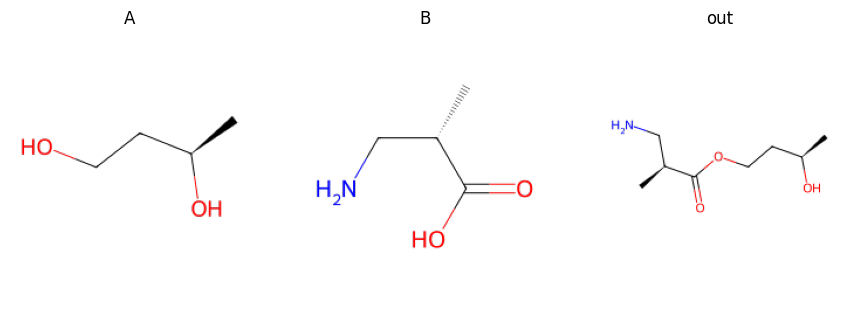

In [ ]:
out = A + B

fig, axs = bam.utils.visual.gallery_grid([A, B, out], ncols=3)
axs[0].set_title("A")
axs[1].set_title("B")
axs[2].set_title("out")

And this even works with our "polymerisation" multiplier:

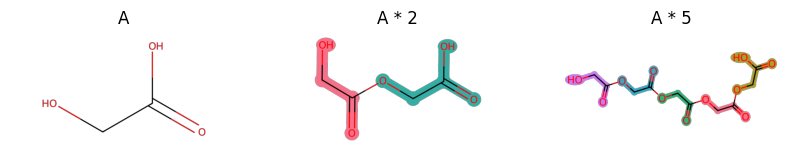

In [ ]:
A = bam.read_smiles("OCC(=O)O")

B = A * 2
C = A * 5


B.name = "A * 2"
C.name = "A * 5"

import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(ncols=3, figsize=(10, 5))
ax[0].imshow(A.draw2d().draw(linewidth=5, fontsize=45))
ax[0].set_title("A")

for i, out in enumerate([B, C]):

    v = out.draw2d()

    palette = sns.color_palette("husl", len(out.residues))
    for r, c in zip(out.residues, palette):
        v.highlight_residues(r, color=c)

    ax[i+1].imshow(v.draw(linewidth=5, fontsize=45))
    ax[i+1].set_title(out.name)

for ax in fig.axes:
    ax.axis("off")

## Customising AutoReact

Whether the ester should have been formed or the N-alkylation should have happened is something we have ultimately in our hand by adjusting the scores of the pairs. So, assuming we feel that under the situation we're assuming the N-alkylation is somehow more likely, we can give that pair a higher score like so:

  #  linkage                         score  target site                  source site                  steric
  0  N-alkylation                    1.115  Hydroxyl elec C1             Amine nucl N2                     9
  1  N-alkylation                    1.115  Hydroxyl elec C4             Amine nucl N2                     9
  2  ester                           0.950  Hydroxyl nucl O2             Carboxyl elec C5                  9
  3  ester                           0.950  Hydroxyl nucl O5             Carboxyl elec C5                 10
  4  ketone (acylation)              0.410  CH nucl C6                   Carboxyl elec C5                 10
  5  ketone (acylation)              0.410  CH nucl C1                   Carboxyl elec C5                 11
  6  ketone (acylation)              0.410  CH nucl C3                   Carboxyl elec C5                 11
  7  ketone (acylation)              0.410  CH nucl C4                   Carboxyl elec C5                 11
  8  C-N [fallback]

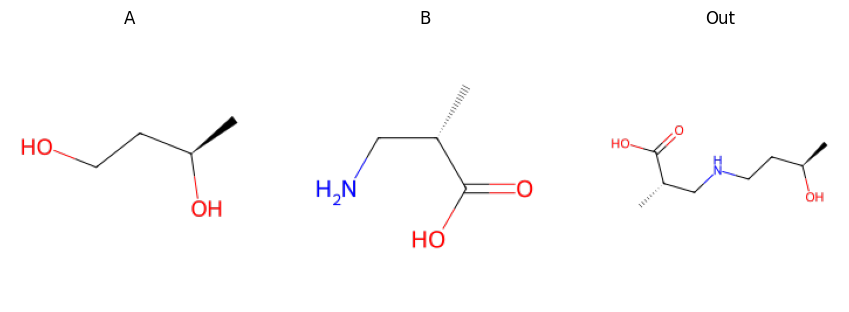

In [33]:
from buildamol.core.autoreact import PairRule, AutoReact

A = bam.read_smiles("C(O)CC(O)C")
B = bam.read_smiles("C(N)C(C)C(=O)O")


# Define an AutoReact instance with specific reaction rules for functional group pairs
# this since Amine + Hydroxyl is already present in the default pairs this will update the rule for this pair only
# here we're giving the Amine+Hydroxyl a score of 1.0 (previously it had 0.3)
R = AutoReact(pairs={
    ("Amine", "Hydroxyl") : PairRule(score=1.0, bond_order=1, label='N-alkylation', fallback=False)
})

out = R(A, B)

fig, axs = bam.utils.visual.gallery_grid([A, B, out], ncols=3)
axs[0].set_title("A")
axs[1].set_title("B")
axs[2].set_title("Out")

print(R.explain(A, B))

And there we have it! Now the carboxyl is left untouched and we instead produce a secondary amine.  

## Identifiying Reactive Sites

What if we only need to scan a molecule for reactive sites without actually connecting them? To do that we can use the `detect_sites` function like so:

In [9]:
from buildamol.structural.reactivity import detect_sites

sites = detect_sites(A)
for s in sites:
    print(s)

Site(Hydroxyl, nucleophile, bonder=O2@1, deletes=['H9'], score=0.50)
Site(Hydroxyl, electrophile, bonder=C1@1, deletes=['O2'], score=0.15)
Site(Hydroxyl, nucleophile, bonder=O5@1, deletes=['H13'], score=0.50)
Site(Hydroxyl, electrophile, bonder=C4@1, deletes=['O5'], score=0.15)
Site(CH, nucleophile, bonder=C1@1, deletes=['H7', 'H8'], score=0.10)
Site(CH, electrophile, bonder=C1@1, deletes=['H7', 'H8'], score=0.10)
Site(CH, nucleophile, bonder=C3@1, deletes=['H10', 'H11'], score=0.10)
Site(CH, electrophile, bonder=C3@1, deletes=['H10', 'H11'], score=0.10)
Site(CH, nucleophile, bonder=C4@1, deletes=['H12'], score=0.10)
Site(CH, electrophile, bonder=C4@1, deletes=['H12'], score=0.10)
Site(CH, nucleophile, bonder=C6@1, deletes=['H14', 'H15', 'H16'], score=0.10)
Site(CH, electrophile, bonder=C6@1, deletes=['H14', 'H15', 'H16'], score=0.10)
